# 01 Eda


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')
#pd.set_option('max_columns', 200)

In [ ]:
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent

data_path = project_root / 'data' / 'raw' / 'PS_20174392719_1491204439457_log.csv'
if not data_path.is_file():
    raise FileNotFoundError(f'Download the PaySim CSV and place it at {data_path}')

df = pd.read_csv(data_path)


In [4]:
df.shape

(6362620, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [7]:
df.tail(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.0,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.0,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.0,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.0,C2080388513,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,C1280323807,850002.52,0.0,C873221189,6510099.11,7360101.63,1,0


In [8]:
df.dtypes

,0
step,int64
type,object
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


In [9]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [10]:
df.isFraud.value_counts()

,count
isFraud,
0,6354407
1,8213


In [11]:
df.nunique()

,0
step,743
type,5
amount,5316900
nameOrig,6353307
oldbalanceOrg,1845844
newbalanceOrig,2682586
nameDest,2722362
oldbalanceDest,3614697
newbalanceDest,3555499
isFraud,2


In [12]:
df.isFraud.value_counts(normalize=True)

,proportion
isFraud,
0,0.998709
1,0.001291


In [13]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [14]:
df.duplicated().sum()

np.int64(0)

The dataset contains 6362620 records and 11 columns and takes about 530MB of storage.
All numerical variables are given as their intended types.
There are no duplicates or missing values.
About 8213 or 0.1291% of transactions are Fraudulent, therefore accuracy cannot be a reliable metric and PR-AUC and Recall should be prioritsed.
Either Class weighting or A hybrid between Undersampling and Oversampling can be used.

## Transaction types and values


In [15]:
df.type.value_counts()

,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


In [16]:
df.groupby('type').isFraud.value_counts()

type      isFraud
CASH_IN   0          1399284
CASH_OUT  0          2233384
          1             4116
DEBIT     0            41432
PAYMENT   0          2151495
TRANSFER  0           528812
          1             4097
Name: count, dtype: int64

In [17]:
df.groupby('type').isFraud.value_counts(normalize=True)

type      isFraud
CASH_IN   0          1.000000
CASH_OUT  0          0.998160
          1          0.001840
DEBIT     0          1.000000
PAYMENT   0          1.000000
TRANSFER  0          0.992312
          1          0.007688
Name: proportion, dtype: float64

In [18]:
df['amount'] <= 0

,amount
0,False
1,False
2,False
3,False
4,False
...,...
6362615,False
6362616,False
6362617,False
6362618,False


In [19]:
df.isFraud.unique()

array([0, 1])

In [20]:
df.isFlaggedFraud.unique()

array([0, 1])

In [21]:
df.step.max()

743

In [22]:
df.step.min()

1

In [23]:
df.step.nunique()

743

The `amount` column has no 0 or negative values. `isFraud` and `isFlaggedFraud` only contain 0 or 1s. The `step` column contains 743 unique values and the max value is 743 so therefore each increment is by 1.

In [24]:
df.amount[df['amount'] == 0].value_counts()

,count
amount,
0.0,16


In [25]:
df.amount[df['amount'] < 0].value_counts()

,count
amount,


In [26]:
df.isFraud[df['amount'] == 0].value_counts()

,count
isFraud,
1,16


There are actually 16 rows with a value of 0 in the `amount` column. There are no negative value rows in the column. All 16 of the 0 valued transactions are classified as Fraud. This might be due to the synthetic nature of the dataset.

## Class imbalance and fraud patterns


In [27]:
(df['isFraud'] == 0).sum() / (df['isFraud'] == 1).sum()

np.float64(773.7010836478753)

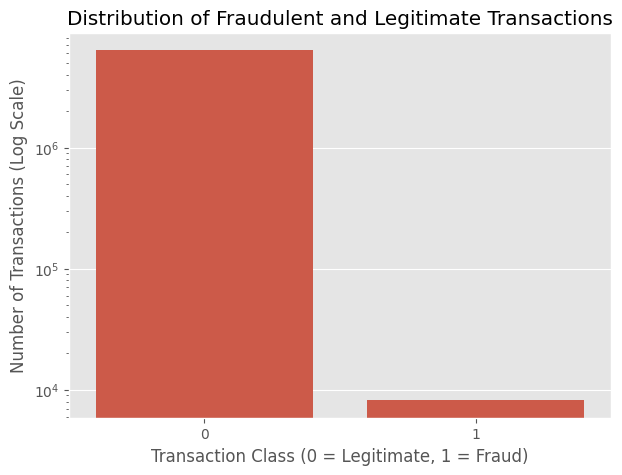

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='isFraud')

plt.yscale('log')
plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions (Log Scale)')

plt.show()

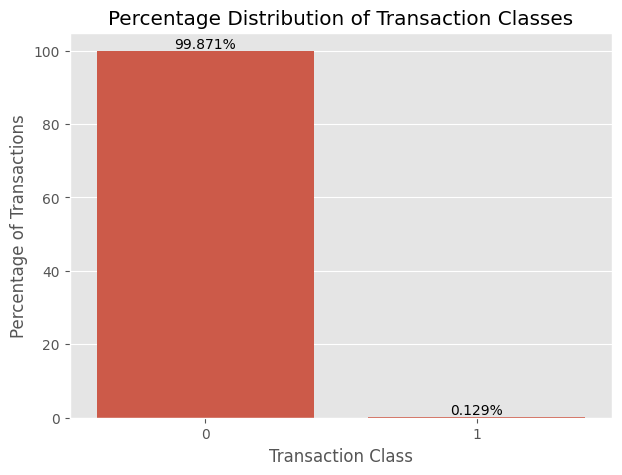

In [29]:
fraud_percentages = df['isFraud'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=fraud_percentages.index,
    y=fraud_percentages.values
)

plt.title('Percentage Distribution of Transaction Classes')
plt.xlabel('Transaction Class')
plt.ylabel('Percentage of Transactions')

for i, percentage in enumerate(fraud_percentages.values):
    ax.text(i, percentage, f'{percentage:.3f}%',
            ha='center', va='bottom')

plt.show()


In [55]:
df_t = df.groupby('type')['isFraud'].agg(['count', 'sum', 'mean']).rename(columns={'count': 'total_transactions', 'sum': 'fraud_count', 'mean': 'fraud_rate'})
df_t['fraud_rate'] = df_t['fraud_rate'] * 100
df_t

,total_transactions,fraud_count,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.183955
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.768799


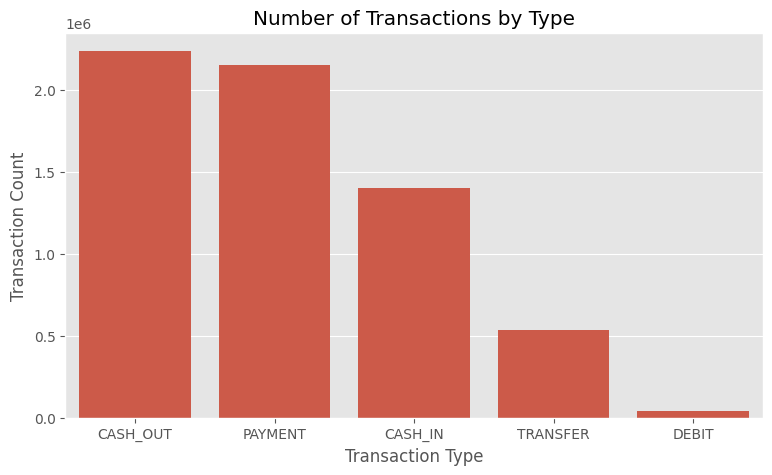

In [56]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='type',
    order=df['type'].value_counts().index
)

plt.title('Number of Transactions by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Transaction Count')
plt.show()

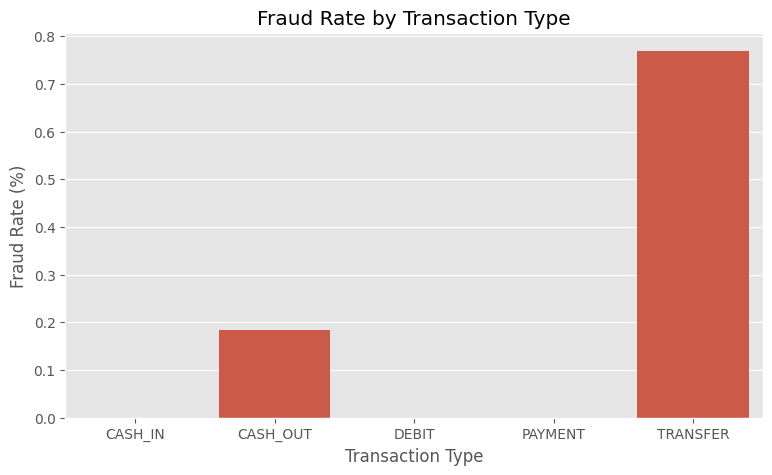

In [57]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_t.reset_index(),
    x='type',
    y='fraud_rate'
)

plt.title('Fraud Rate by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Rate (%)')
plt.show()

In [68]:
df.amount.describe()

,amount
count,6.362620e+06
mean,1.798619e+05
std,6.038582e+05
min,0.000000e+00
25%,1.338957e+04
50%,7.487194e+04
75%,2.087215e+05
max,9.244552e+07


In [69]:
df.amount.median()

74871.94

In [72]:
df.amount.quantile([0.9, 0.95, 0.99])

,amount
0.90,3.654233e+05
0.95,5.186342e+05
0.99,1.615979e+06


In [74]:
df.amount.skew()

np.float64(30.99394948249038)

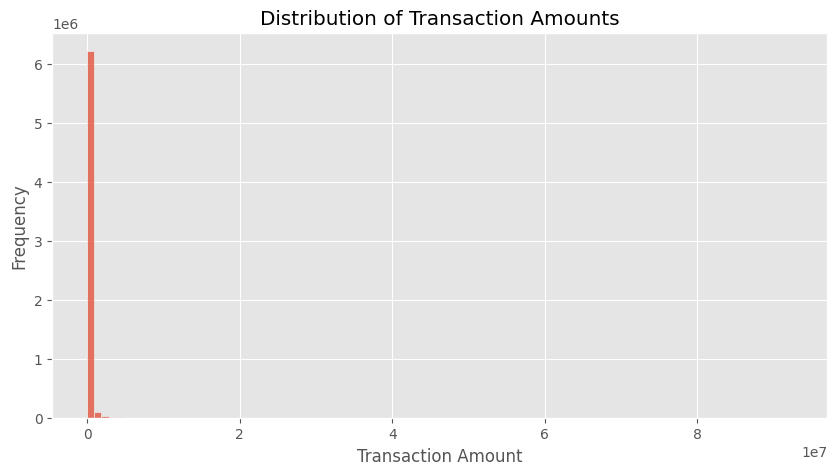

In [75]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='amount',
    bins=100
)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

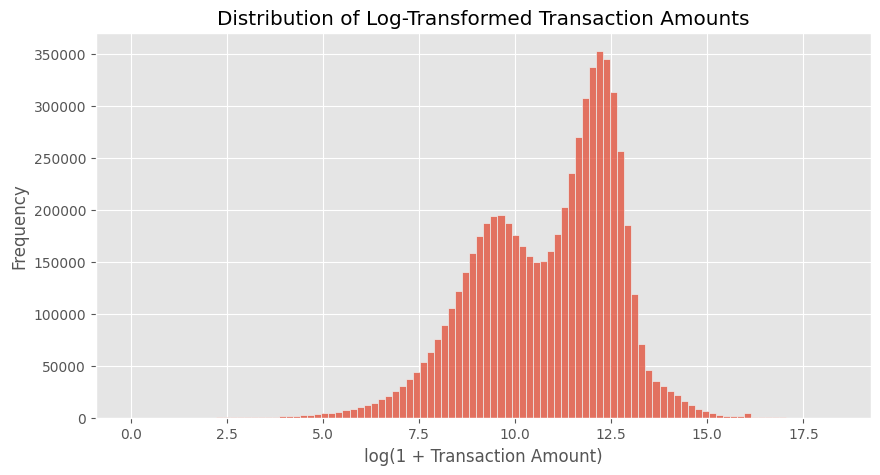

In [76]:
plt.figure(figsize=(10, 5))

sns.histplot(
    x=np.log1p(df['amount']),
    bins=100
)

plt.title('Distribution of Log-Transformed Transaction Amounts')
plt.xlabel('log(1 + Transaction Amount)')
plt.ylabel('Frequency')

plt.show()

In [79]:
df.groupby('isFraud').amount.describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


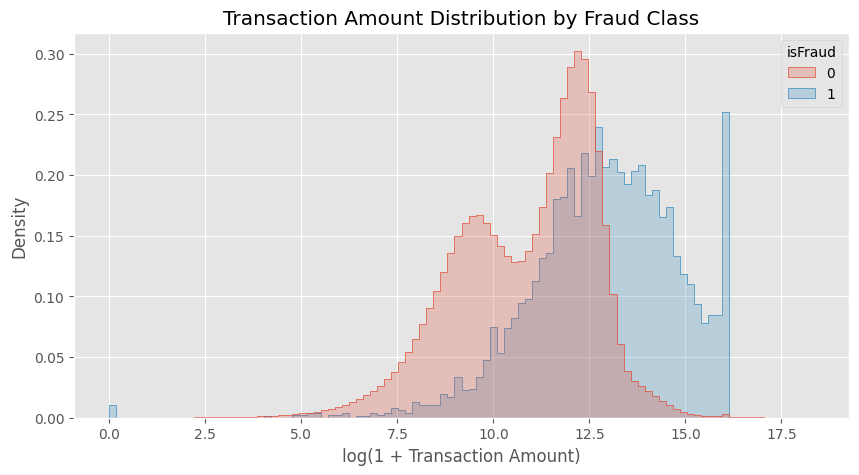

In [83]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=np.log1p(df['amount']),
    hue='isFraud',
    bins=100,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Transaction Amount Distribution by Fraud Class')
plt.xlabel('log(1 + Transaction Amount)')
plt.ylabel('Density')
plt.show()

In [93]:
bins = [0, 10000, 50000, 100000, 500000, 1000000, float('inf')]
df['amount_bin'] = pd.cut(df['amount'], bins=bins, include_lowest=True)
amount_summary = df.groupby('amount_bin').isFraud.agg(['count', 'sum', 'mean']).rename(columns={'count':'Total Transactions', 'sum':'Fraudulent Transactions', 'mean':'Fraud Rate'})
amount_summary['Fraud Rate'] *= 100
amount_summary

/tmp/ipykernel_459/827839383.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  amount_summary = df.groupby('amount_bin').isFraud.agg(['count', 'sum', 'mean']).rename(columns={'count':'Total Transactions', 'sum':'Fraudulent Transactions', 'mean':'Fraud Rate'})


,Total Transactions,Fraudulent Transactions,Fraud Rate
amount_bin,,,
"(-0.001, 10000.0]",1286091,278,0.021616
"(10000.0, 50000.0]",1519856,760,0.050005
"(50000.0, 100000.0]",719351,669,0.093000
"(100000.0, 500000.0]",2497038,2642,0.105805
"(500000.0, 1000000.0]",209658,1158,0.552328
"(1000000.0, inf]",130626,2706,2.071563


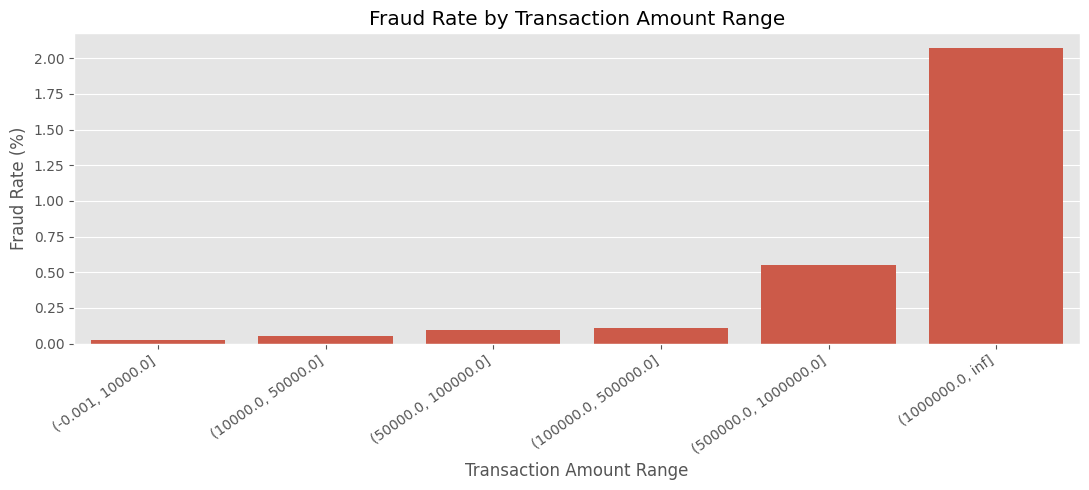

In [95]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=amount_summary.index.astype(str),
    y=amount_summary['Fraud Rate']
)

plt.title('Fraud Rate by Transaction Amount Range')
plt.xlabel('Transaction Amount Range')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

In [119]:
bins = [0, 10000, 50000, 100000, 500000, 1000000, float('inf')]
df['amount_bin'] = pd.cut(df['amount'], bins=bins, include_lowest=True)
type_amount_summary = df.groupby(['type', 'amount_bin']).isFraud.agg(['count', 'sum', 'mean']).rename(columns={'count':'Total Transactions', 'sum':'Fraudulent Transactions', 'mean':'Fraud Rate'})
type_amount_summary['Fraud Rate'] *= 100
type_amount_summary

/tmp/ipykernel_459/125866874.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  type_amount_summary = df.groupby(['type', 'amount_bin']).isFraud.agg(['count', 'sum', 'mean']).rename(columns={'count':'Total Transactions', 'sum':'Fraudulent Transactions', 'mean':'Fraud Rate'})


Total Transactions  Fraudulent Transactions  \
type     amount_bin                                                           
CASH_IN  (-0.001, 10000.0]                   47692                        0   
         (10000.0, 50000.0]                 198263                        0   
         (50000.0, 100000.0]                251493                        0   
         (100000.0, 500000.0]               875855                        0   
         (500000.0, 1000000.0]               25862                        0   
         (1000000.0, inf]                      119                        0   
CASH_OUT (-0.001, 10000.0]                   72761                      147   
         (10000.0, 50000.0]                 307396                      382   
         (50000.0, 100000.0]                393912                      336   
         (100000.0, 500000.0]              1410198                     1327   
         (500000.0, 1000000.0]               51585                      579   
         (1000000.0, inf]                     1648                     1345   
DEBIT    (-0.001, 10000.0]                   37648                        0   
         (10000.0, 50000.0]                   3358                        0   
         (50000.0, 100000.0]                   273                        0   
         (100000.0, 500000.0]                  151                        0   
         (500000.0, 1000000.0]                   2                        0   
         (1000000.0, inf]                        0                        0   
PAYMENT  (-0.001, 10000.0]                 1121906                        0   
         (10000.0, 50000.0]                 986067                        0   
         (50000.0, 100000.0]                 42486                        0   
         (100000.0, 500000.0]                 1036                        0   
         (500000.0, 1000000.0]                   0                        0   
         (1000000.0, inf]                        0                        0   
TRANSFER (-0.001, 10000.0]                    6084                      131   
         (10000.0, 50000.0]                  24772                      378   
         (50000.0, 100000.0]                 31187                      333   
         (100000.0, 500000.0]               209798                     1315   
         (500000.0, 1000000.0]              132209                      579   
         (1000000.0, inf]                   128859                     1361   

                                Fraud Rate  
type     amount_bin                         
CASH_IN  (-0.001, 10000.0]        0.000000  
         (10000.0, 50000.0]       0.000000  
         (50000.0, 100000.0]      0.000000  
         (100000.0, 500000.0]     0.000000  
         (500000.0, 1000000.0]    0.000000  
         (1000000.0, inf]         0.000000  
CASH_OUT (-0.001, 10000.0]        0.202031  
         (10000.0, 50000.0]       0.124270  
         (50000.0, 100000.0]      0.085298  
         (100000.0, 500000.0]     0.094100  
         (500000.0, 1000000.0]    1.122419  
         (1000000.0, inf]        81.614078  
DEBIT    (-0.001, 10000.0]        0.000000  
         (10000.0, 50000.0]       0.000000  
         (50000.0, 100000.0]      0.000000  
         (100000.0, 500000.0]     0.000000  
         (500000.0, 1000000.0]    0.000000  
         (1000000.0, inf]              NaN  
PAYMENT  (-0.001, 10000.0]        0.000000  
         (10000.0, 50000.0]       0.000000  
         (50000.0, 100000.0]      0.000000  
         (100000.0, 500000.0]     0.000000  
         (500000.0, 1000000.0]         NaN  
         (1000000.0, inf]              NaN  
TRANSFER (-0.001, 10000.0]        2.153189  
         (10000.0, 50000.0]       1.525916  
         (50000.0, 100000.0]      1.067753  
         (100000.0, 500000.0]     0.626793  
         (500000.0, 1000000.0]    0.437943  
         (1000000.0, inf]         1.056193

In [120]:
plot_df = type_amount_summary.loc[['TRANSFER', 'CASH_OUT']].reset_index()

plot_df['amount_bin'] = plot_df['amount_bin'].astype(str)

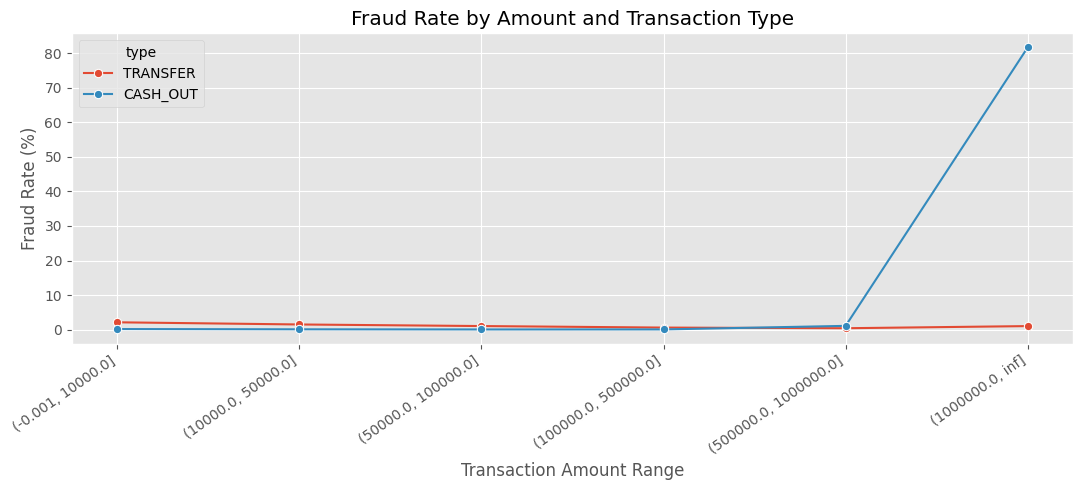

In [121]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=plot_df,
    x='amount_bin',
    y='Fraud Rate',
    hue='type',
    marker='o',
    sort=False,
    estimator=None
)

plt.title('Fraud Rate by Amount and Transaction Type')
plt.xlabel('Transaction Amount Range')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()


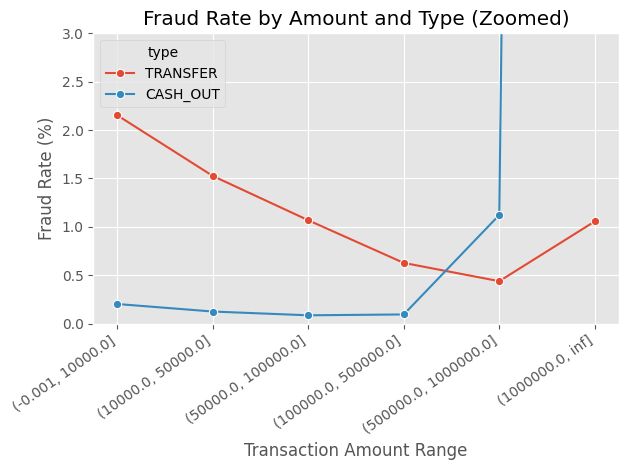

In [123]:
sns.lineplot(
    data=plot_df,
    x='amount_bin',
    y='Fraud Rate',
    hue='type',
    marker='o',
    sort=False,
    estimator=None
)

plt.ylim(0, 3)
plt.title('Fraud Rate by Amount and Type (Zoomed)')
plt.xlabel('Transaction Amount Range')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

In PaySim, CASH_OUT transactions exceeding 1 million exhibit an unusually high fraud rate of 81.61%, with 1,345 fraudulent transactions among 1,648 observations. This suggests a strong relationship between transaction type and amount in the synthetic dataset. However, this pattern may be influenced by PaySim's simulation rules and should not be assumed to generalize to real-world payment systems.

## Balance fields and leakage risk


In [141]:
df['discrepancy'] = df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']

In [148]:
df.groupby(['type', 'isFraud']).discrepancy.describe()

count           mean           std          min  \
type     isFraud                                                        
CASH_IN  0        1399284.0 -337835.445783  2.530129e+05  -3830535.80   
CASH_OUT 0        2233384.0 -147994.192774  1.322744e+05  -2847566.62   
         1           4116.0   -1306.125231  2.067385e+04   -577418.98   
DEBIT    0          41432.0   -1997.980151  1.083029e+04   -569077.51   
PAYMENT  0        2151495.0   -6678.667998  1.117811e+04   -238637.98   
TRANSFER 0         528812.0 -873050.622427  1.874245e+06 -92445516.64   
         1           4097.0  -20122.054174  3.746216e+05 -10000000.00   

                          25%         50%          75%           max  
type     isFraud                                                      
CASH_IN  0       -479793.6450 -286848.820 -141017.4675 -8.000000e-02  
CASH_OUT 0       -221267.7775 -119824.215  -41950.4525  1.000000e-02  
         1             0.0000       0.000       0.0000  0.000000e+00  
DEBIT    0          -711.1500       0.000       0.0000  1.000000e-02  
PAYMENT  0         -9654.0450    -380.780       0.0000  1.000000e-02  
TRANSFER 0       -937662.3525 -454033.080 -184686.1475  1.000000e-02  
         1             0.0000       0.000       0.0000  3.725290e-09

In [159]:
balance_df = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()
balance_df['discrepancy_zero'] = (balance_df['discrepancy'].abs() <= 0.01)

In [161]:
(balance_df.groupby(['type', 'isFraud']).discrepancy_zero.mean()) * 100

type      isFraud
CASH_OUT  0          10.841799
          1          99.416910
TRANSFER  0           3.791707
          1          99.487430
Name: discrepancy_zero, dtype: float64

In [162]:
balance_df['balance_unchanged'] = ((balance_df['oldbalanceOrg'] - balance_df['newbalanceOrig']).abs() <= 0.01)
(balance_df.groupby(['type', 'isFraud']).balance_unchanged.mean()) * 100

type      isFraud
CASH_OUT  0          45.928689
          1           0.898931
TRANSFER  0          53.474581
          1           0.488162
Name: balance_unchanged, dtype: float64

In [163]:
balance_df['both_balances_zero'] = ((balance_df['oldbalanceOrg'] == 0) & (balance_df['newbalanceOrig'] == 0))
(balance_df.groupby(['type', 'isFraud']).both_balances_zero.mean()) * 100

type      isFraud
CASH_OUT  0          45.928600
          1           0.898931
TRANSFER  0          53.474392
          1           0.097632
Name: both_balances_zero, dtype: float64

In [164]:
df['dest_discrepancy'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']

In [165]:
balance_df = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()
balance_df['dest_discrepancy_zero'] = (balance_df['dest_discrepancy'].abs() <= 0.01)

In [166]:
(balance_df.groupby(['type', 'isFraud']).dest_discrepancy_zero.mean()) * 100

type      isFraud
CASH_OUT  0          77.304351
          1          86.758989
TRANSFER  0          77.928640
          1           0.048816
Name: dest_discrepancy_zero, dtype: float64

In [167]:
balance_df['both_balances_zero'] = ((balance_df['oldbalanceDest'] == 0) & (balance_df['newbalanceDest'] == 0))
(balance_df.groupby(['type', 'isFraud']).both_balances_zero.mean()) * 100

type      isFraud
CASH_OUT  0           0.071640
          1           0.194363
TRANSFER  0           0.020045
          1          99.292165
Name: both_balances_zero, dtype: float64

Balance-related features exhibit unusually strong associations with fraud labels in PaySim. Approximately 99.5% of fraudulent outgoing transactions have near-zero originating balance discrepancies, while 99.29% of fraudulent TRANSFER transactions have both destination balances recorded as zero. These patterns may reflect simulation-specific behavior or transaction processing outcomes. Therefore, all four balance columns and their derived features will be excluded from the primary fraud detection model to reduce data leakage risk.

## Changes across simulation time


In [168]:
df['day'] = ((df['step'] - 1) // 24) + 1

In [170]:
df['day'].head()

,day
0,1
1,1
2,1
3,1
4,1


In [173]:
daily_counts = df.groupby('day').size()

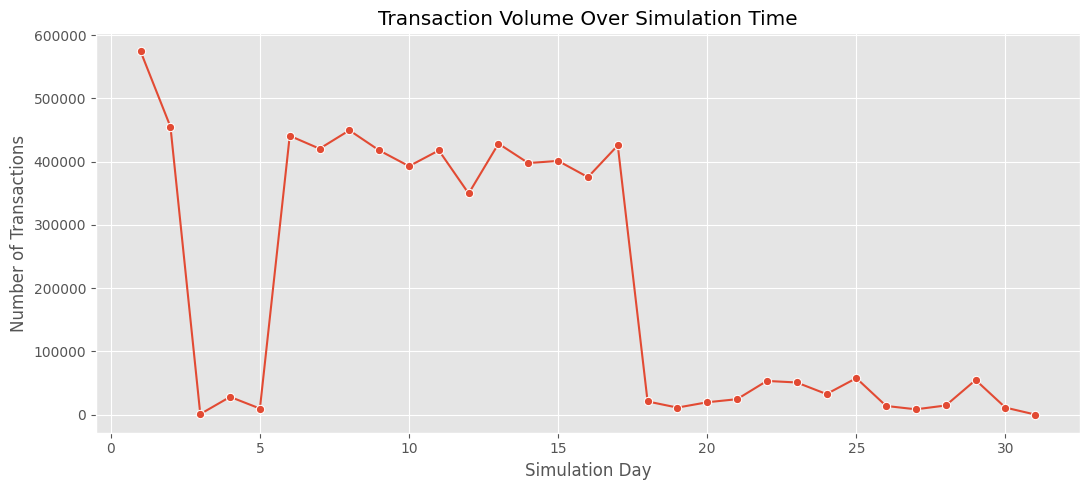

In [174]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    x=daily_counts.index,
    y=daily_counts.values,
    marker='o'
)

plt.title('Transaction Volume Over Simulation Time')
plt.xlabel('Simulation Day')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

In [176]:
daily_summary = df.groupby('day').isFraud.agg(['count', 'sum', 'mean']).rename(columns={'count':'Total Transactions', 'sum':'Fraudulent Transactions', 'mean':'Fraud Rate'})
daily_summary['Fraud Rate'] *= 100
daily_summary

,Total Transactions,Fraudulent Transactions,Fraud Rate
day,,,
1,574255,271,0.047192
2,455238,309,0.067877
3,1070,310,28.971963
4,28240,262,0.927762
5,9789,252,2.574318
6,441005,228,0.051700
7,420583,272,0.064672
8,449637,278,0.061828
9,417919,255,0.061017


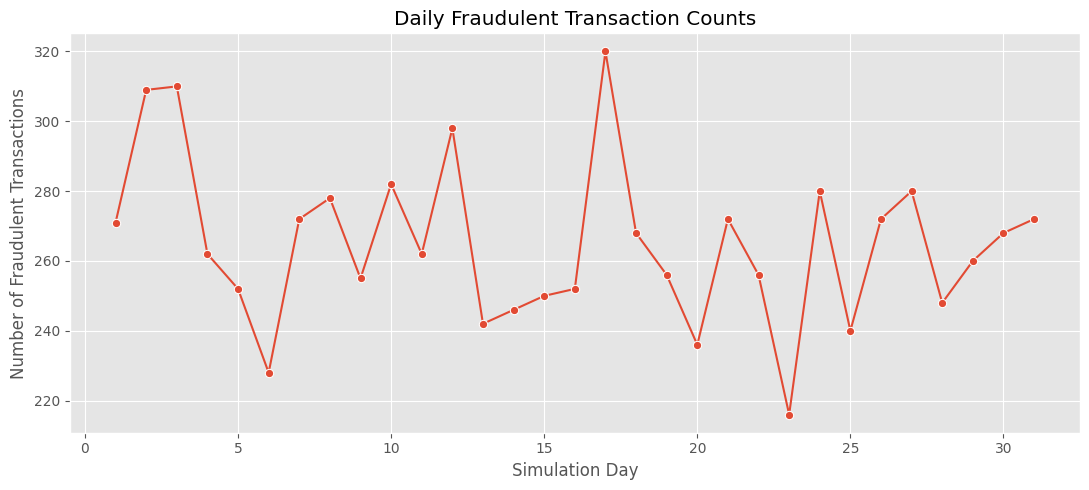

In [178]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=daily_summary.reset_index(),
    x='day',
    y='Fraudulent Transactions',
    marker='o'
)

plt.title('Daily Fraudulent Transaction Counts')
plt.xlabel('Simulation Day')
plt.ylabel('Number of Fraudulent Transactions')

plt.tight_layout()
plt.show()

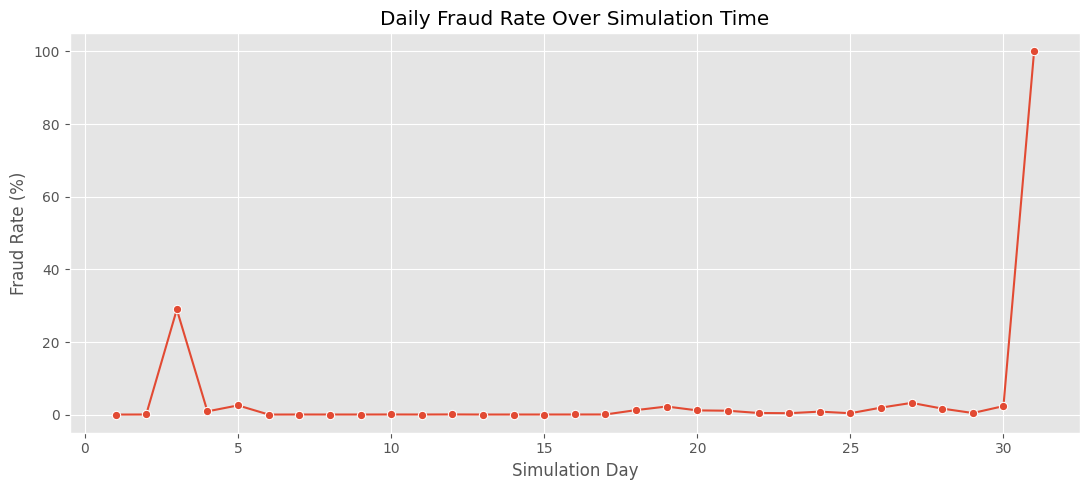

In [179]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=daily_summary.reset_index(),
    x='day',
    y='Fraud Rate',
    marker='o'
)

plt.title('Daily Fraud Rate Over Simulation Time')
plt.xlabel('Simulation Day')
plt.ylabel('Fraud Rate (%)')

plt.tight_layout()
plt.show()

In [184]:
day31 = df[df['day'] == 31]

In [190]:
day31.shape

(272, 15)

In [188]:
day31.isFraud.value_counts()

,count
isFraud,
1,272


In [189]:
day31.groupby('type').isFraud.value_counts()

,,count
type,isFraud,
CASH_OUT,1,136
TRANSFER,1,136


In [191]:
df['period'] = np.where(df['day'] <= 17, 'Early', 'Late')

In [194]:
df.groupby('period').size()

,0
period,
Early,5987417
Late,375203


In [195]:
(df.groupby('period').isFraud.mean()) * 100

,isFraud
period,
Early,0.076644
Late,0.965877


In [196]:
time_transaction = pd.crosstab(index=df['period'], columns=df['type'], normalize='index')
time_transaction

type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
period,,,,,
Early,0.219358,0.353791,0.006428,0.337327,0.083096
Late,0.228929,0.317716,0.007844,0.351218,0.094293


In [197]:
df.groupby('period').amount.median()

,amount
period,
Early,75244.27
Late,69171.52


## Account identifiers and existing fraud flag


In [204]:
(df['nameOrig'].value_counts() == 1).sum()

np.int64(6344009)

In [205]:
(df['nameDest'].value_counts() == 1).sum()

np.int64(2262704)

In [207]:
(df['nameOrig'].value_counts()).max()

3

In [212]:
(df['nameDest'].value_counts()).max()

113

In [211]:
((df['nameOrig'].value_counts() == 1).sum() / df['nameOrig'].nunique()) * 100

np.float64(99.8536510198547)

In [213]:
(df['nameOrig'].str[0] == 'C').sum()

np.int64(6362620)

In [214]:
(df['nameOrig'].str[0] == 'M').sum()

np.int64(0)

In [215]:
(df['nameDest'].str[0] == 'C').sum()

np.int64(4211125)

In [216]:
(df['nameDest'].str[0] == 'M').sum()

np.int64(2151495)

In [220]:
df['prefix'] = np.where(df['nameDest'].str[0].isin(['M']), 'Merchant', 'Customer')

In [221]:
df.groupby('prefix').isFraud.value_counts(normalize=True)

prefix    isFraud
Customer  0          0.99805
          1          0.00195
Merchant  0          1.00000
Name: proportion, dtype: float64

In [222]:
pd.crosstab(index=df['prefix'], columns=df['type'], normalize='index')

type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
prefix,,,,,
Customer,0.332283,0.531331,0.009839,0.0,0.126548
Merchant,0.000000,0.000000,0.000000,1.0,0.000000


In [223]:
pd.crosstab(index=df['isFraud'], columns=df['isFlaggedFraud'])

isFlaggedFraud,0,1
isFraud,,
0,6354407,0
1,8197,16


In [225]:
precision = (16) / (16 + 0)
precision

1.0

In [226]:
recall = (16) / (16 + 8197)
recall

0.0019481310118105442

| Finding | Evidence from EDA | Modelling Implication |
| :--- | :---: | ---: |
| Class Imbalance | Fraud rate of ~0.129% | Use P-R Metrics |
| Transaction amount skew | Skewness of ~30.99 | Consider log transformation |
| All fraud are `TRANSFER` or `CASH_OUT` | 4097 and 4116 fraud in each | `type` is a good feature |
| `CASH_OUT` above 1M likely fraud| Fraud Rate of ~81.61% | Combining `type` and `amount` might be useful |
| Balance-related leakage | Strong balance-fraud associations | Exclude balance columns |
| Temporal distribution changes | Different early/late fraud rates | Evaluate chronologically |
| Account identifier limitations | Most origin accounts appear once | Exclude raw account IDs |
| Existing rule limitations | Precision 100%, recall 0.195% | Compare against an ML baseline |